# 02 · Retrieval Experiments — Which Search Method Finds the Right Note?
**Project 2 — RAG Notes Assistant.** Previous: [01 Corpus & chunking](01_corpus_and_chunking.ipynb).

The retriever decides what the chatbot can possibly answer: if the right passage isn't retrieved, no language model can fix that. So we **measure** retrieval on a hand-written question set instead of guessing.

**Method (important for honesty):**
1. 62 in-scope questions, written by hand and *paraphrased* (they avoid copying the heading words), each with the acceptable right answer(s).
2. Split into **dev** (31, used for every tuning decision) and **test** (31, looked at only after the settings were frozen).
3. Small numbers: one question is ≈ 3 percentage points. Differences of a few points are **noise** — we say so when it happens.

In [1]:
import sys, time, json, warnings; warnings.filterwarnings('ignore'); sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from rag_notes.index import Index
from rag_notes.retrievers import HybridRetriever, CharNgramRetriever
from rag_notes.evaluate import load_golden, validate_targets, retrieval_metrics, rank_of_first_hit, matches
sns.set_theme(style='whitegrid')
golden = load_golden('eval/golden.json')
dev  = [i for i in golden['in_scope'] if i['split']=='dev']
test = [i for i in golden['in_scope'] if i['split']=='test']
print(len(golden['in_scope']), 'in-scope questions →', len(dev), 'dev /', len(test), 'test')

62 in-scope questions → 31 dev / 31 test


## 1. The evaluation set

In [2]:
pd.DataFrame([dict(id=i['id'], question=i['question'], right_answer=i['targets'][0][1], file=i['targets'][0][0].split('/')[0], split=i['split']) for i in golden['in_scope']]).head(12)

,id,question,right_answer,file,split
0,in00,Why is a NumPy array faster than a Python list?,Why NumPy instead,numpy,dev
1,in01,"If I change a slice of an array, does the orig...",Views vs Copies,numpy,test
2,in02,How can I turn a 1-D array of 12 numbers into ...,reshape(),numpy,dev
3,in03,What is the difference between ravel and flatten?,vs `flatten()`,numpy,test
4,in04,How do I find the position of the largest elem...,argmax(),numpy,dev
5,in05,How do I get the order of indices that would s...,argsort(),numpy,test
6,in06,How can I remove duplicate values from an array?,np.unique(),numpy,dev
7,in07,How do I test whether each element belongs to ...,isin(),numpy,test
8,in08,How do I add a border of zeros around a matrix?,np.pad(),numpy,dev
9,in09,How do I shift array elements around circularly?,np.roll(),numpy,test


In [3]:
pd.DataFrame([i['targets'][0][0].split('/')[0] for i in golden['in_scope']], columns=['series']).value_counts().to_frame('questions')

,questions
series,
numpy,20
pandas,14
scikit-learn,10
matplotlib,8
seaborn,5
exercises,3
interview-qa,2


In [4]:
pd.Series([len(i['targets']) for i in golden['in_scope']]).value_counts().rename_axis('acceptable answers').to_frame('questions')

,questions
acceptable answers,
1,54
2,7
3,1


Some questions have **several acceptable answers** (e.g. “count how many times each value appears” is covered in both the Pandas basics notebook and the interview Q&A).

In [5]:
pd.Series([len(i['question'].split()) for i in golden['in_scope']]).describe().round(1).to_frame('words per question')

,words per question
count,62.0
mean,10.8
std,2.2
min,7.0
25%,9.0
50%,11.0
75%,12.0
max,17.0


### 1.1 Do all “right answers” really exist in the corpus?

In [6]:
index = Index.build('data/notes'); print(len(index.chunks), 'chunks')
print('targets that do not exist in the corpus:', validate_targets(index, golden))

582 chunks
targets that do not exist in the corpus: []


A typo in the answer key would silently lower every score, so we check each target exists. (This check caught one wrong heading while building the set.)

### 1.2 How is a result judged correct?

In [7]:
item = golden['in_scope'][4]; print(item['question']); print('acceptable:', item['targets'])
for r,(c,s) in enumerate(index.search(item['question'], k=5), 1): print(r, 'CORRECT' if matches(c,item['targets']) else '       ', c.source.split('/')[-1], '›', c.section.split(' > ')[-1][:55])

How do I find the position of the largest element in an array?
acceptable: [['numpy/05_searching_sorting_filtering', 'argmax()']]
1         01_pandas_basics.md › 4. Accessing Series Elements
2         05_searching_sorting_filtering.md › 7. `np.nonzero()` — Locating Non-Zero Elements
3         05_searching_sorting_filtering.md › 2. `np.searchsorted()` — Binary Search Insert Position
4         03_indexing_selecting.md › 2. `iloc[]` — Position-Based Selection
5         01_matplotlib_basics.md › Legends & Positioning


A retrieved chunk counts as correct if it comes from the right file **and** contains the right heading. Metrics:

| Metric | Meaning |
|---|---|
| **hit@k** | share of questions whose right answer is in the top *k* results |
| **MRR** | mean of 1/rank of the first right answer (1.0 = always first) |

## 2. Baselines on the dev questions

In [8]:
def report(idx, items, methods=('bm25','char','lsa','hybrid')):
    rows={}
    for m in methods:
        r,_=retrieval_metrics(idx, items, m); rows[m]=r
    return pd.DataFrame(rows).T[['hit@1','hit@3','hit@5','hit@10','MRR']].round(3)
base = Index.build('data/notes', drop_nav=False, kind_weights={}, heading_boost=1)
report(base, dev)

,hit@1,hit@3,hit@5,hit@10,MRR
bm25,0.387,0.613,0.645,0.710,0.516
char,0.290,0.484,0.516,0.581,0.388
lsa,0.194,0.452,0.613,0.710,0.356
hybrid,0.387,0.484,0.581,0.742,0.461


*(Disclosure: before the dev/test split was used I ran one quick benchmark over all 62 questions to see whether the pipeline worked at all. All tuning below uses dev only.)*

**Reading the table:** on the dev questions BM25 (keyword search) is the strongest single method (best MRR). LSA (a small embedding trained on these notes only) and character n-grams (which should help with glued API names such as `fillna`) are weaker here. The numbers are low overall: roughly 6 in 10 questions have the right passage in the top 3.

### 2.1 Why does it fail? Look at the failures

In [9]:
_,ranks = retrieval_metrics(base, dev, 'bm25')
for it,rk in zip(dev,ranks):
    if rk is None or rk>3:
        top=base.search(it['question'],2,'bm25')
        print(f"[rank {rk}] {it['question']}\n    wanted: {it['targets'][0][1]}   got: " + ' || '.join(c.source.split('/')[-1][:16]+' › '+c.section.split(' > ')[-1][:34] for c,_ in top))

[rank None] How can I turn a 1-D array of 12 numbers into a 3x4 table?
    wanted: reshape()   got: 100_numpy_exerci › 87. Consider a 16x16 array, how to || 01_numpy_basics. › 15. `np.vectorize()` — Turning a P
[rank None] How do I find the position of the largest element in an array?
    wanted: argmax()   got: 100_numpy_exerci › 89. How to get the n largest value || 05_searching_sor › 7. `np.nonzero()` — Locating Non-Z
[rank None] How can I remove duplicate values from an array?
    wanted: np.unique()   got: 04_pandas_interv › Q24. (Bonus) Find and remove dupli || 04_data_cleaning › 15. Summary — What You Learned
[rank 8] How do I add a border of zeros around a matrix?
    wanted: np.pad()   got: 100_numpy_exerci › 16. How to add a border (filled wi || 01_matplotlib_ba › Spines Control — Customizing Plot 
[rank None] What does -1 mean when reshaping an array?
    wanted: Using `-1`   got: 100_numpy_exerci › 100. Compute bootstrapped 95% conf || 04_reshaping_sta › 1. `reshape()` — Ch

A pattern: many wrong results are tiny **exercise questions** (“How to …”) from the *100 NumPy exercises* list. Short texts get an unfair boost in BM25 (length normalisation) and they contain generic words like *array*, *how*.

In [10]:
rows=[]
for it in dev:
    top=base.search(it['question'],3,'bm25'); rows.append(sum(c.kind=='exercises' for c,_ in top)/max(len(top),1))
print('Average share of the top-3 results that are exercise questions: %.0f%% (exercises are only %.0f%% of all chunks)' % (np.mean(rows)*100, np.mean([c.kind=='exercises' for c in base.chunks])*100))

Average share of the top-3 results that are exercise questions: 20% (exercises are only 16% of all chunks)


Exercises are ~16% of chunks and ~20% of top-3 results — only a modest over-representation overall, but they appear in several of the failures above. We try three cheap fixes: drop navigation chunks, **down-weight** the exercises, and boost headings, and then re-check whether the crowding is really gone (§5.1).

## 3. Ablations (dev only)

### 3.1 Drop navigation chunks

In [11]:
a1 = Index.build('data/notes', drop_nav=True, kind_weights={}, heading_boost=1)
pd.concat({'keep nav chunks':report(base,dev,('bm25','hybrid')),'drop nav chunks':report(a1,dev,('bm25','hybrid'))})

hit@1  hit@3  hit@5  hit@10    MRR
keep nav chunks bm25    0.387  0.613  0.645   0.710  0.516
                hybrid  0.387  0.484  0.581   0.742  0.461
drop nav chunks bm25    0.484  0.613  0.677   0.710  0.568
                hybrid  0.419  0.516  0.710   0.742  0.513

### 3.2 Down-weight exercise chunks

In [12]:
rows=[]
for w in [1.0,0.8,0.6,0.4,0.2]:
    ix=Index.build('data/notes', drop_nav=True, kind_weights={'exercises':w}, heading_boost=1)
    for m in ['bm25','hybrid']:
        r,_=retrieval_metrics(ix,dev,m); rows.append(dict(weight=w,method=m,**{k:round(v,3) for k,v in r.items() if k!='n'}))
w_df=pd.DataFrame(rows); w_df.pivot(index='weight',columns='method',values='hit@3').join(w_df.pivot(index='weight',columns='method',values='MRR'),lsuffix=' hit@3',rsuffix=' MRR')

method,bm25 hit@3,hybrid hit@3,bm25 MRR,hybrid MRR
weight,,,,
0.2,0.645,0.613,0.572,0.554
0.4,0.645,0.613,0.593,0.554
0.6,0.645,0.613,0.592,0.559
0.8,0.613,0.645,0.569,0.583
1.0,0.613,0.516,0.568,0.513


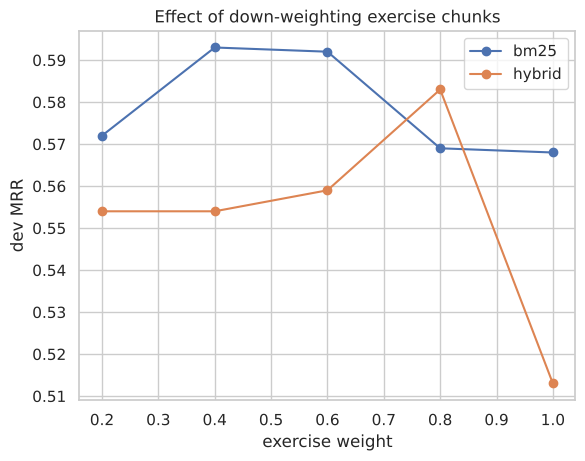

In [13]:
for m,g in w_df.groupby('method'): plt.plot(g.weight,g.MRR,'o-',label=m)
plt.xlabel('exercise weight'); plt.ylabel('dev MRR'); plt.legend(); plt.title('Effect of down-weighting exercise chunks'); plt.show()

### 3.3 Boost the headings (repeat the heading in the indexed text)

In [14]:
rows=[]
for hb in [1,2,3]:
    ix=Index.build('data/notes', drop_nav=True, kind_weights={'exercises':0.6}, heading_boost=hb)
    for m in ['bm25','hybrid']:
        r,_=retrieval_metrics(ix,dev,m); rows.append(dict(heading_boost=hb,method=m,**{k:round(v,3) for k,v in r.items() if k!='n'}))
pd.DataFrame(rows)

,heading_boost,method,hit@1,hit@3,hit@5,hit@10,MRR
0,1,bm25,0.516,0.645,0.677,0.742,0.592
1,1,hybrid,0.484,0.613,0.742,0.742,0.559
2,2,bm25,0.548,0.645,0.710,0.742,0.609
3,2,hybrid,0.419,0.581,0.742,0.742,0.521
4,3,bm25,0.516,0.645,0.710,0.774,0.604
5,3,hybrid,0.387,0.613,0.742,0.742,0.508


### 3.4 BM25 length-normalisation parameter `b`

In [15]:
rows=[]
for b in [0.3,0.5,0.75,0.9,1.0]:
    ix=Index.build('data/notes', drop_nav=True, kind_weights={'exercises':0.6}, heading_boost=2, bm25_b=b)
    r,_=retrieval_metrics(ix,dev,'bm25'); rows.append(dict(b=b,**{k:round(v,3) for k,v in r.items() if k!='n'}))
pd.DataFrame(rows)

,b,hit@1,hit@3,hit@5,hit@10,MRR
0,0.30,0.613,0.645,0.71,0.774,0.650
1,0.50,0.613,0.645,0.71,0.774,0.650
2,0.75,0.548,0.645,0.71,0.742,0.609
3,0.90,0.548,0.645,0.71,0.742,0.609
4,1.00,0.548,0.645,0.71,0.742,0.609


### 3.5 Chunk size

In [16]:
rows=[]
for mx,mn in [(400,0),(800,200),(1200,200),(2000,200),(4000,200)]:
    ix=Index.build('data/notes', max_chars=mx, min_chars=mn, kind_weights={'exercises':0.6}, heading_boost=2)
    if validate_targets(ix,golden): rows.append(dict(max_chars=mx,min_chars=mn,note='some targets vanished (heading merged away)')); continue
    for m in ['bm25','hybrid']:
        r,_=retrieval_metrics(ix,dev,m); rows.append(dict(max_chars=mx,min_chars=mn,n_chunks=len(ix.chunks),method=m,**{k:round(v,3) for k,v in r.items() if k!='n'}))
pd.DataFrame(rows)

,max_chars,min_chars,n_chunks,method,hit@1,hit@3,hit@5,hit@10,MRR
0,400,0,899,bm25,0.484,0.645,0.710,0.742,0.578
1,400,0,899,hybrid,0.419,0.548,0.742,0.774,0.532
2,800,200,635,bm25,0.516,0.645,0.710,0.742,0.593
3,800,200,635,hybrid,0.419,0.516,0.742,0.742,0.507
4,1200,200,582,bm25,0.548,0.645,0.710,0.742,0.609
5,1200,200,582,hybrid,0.419,0.581,0.742,0.742,0.521
6,2000,200,576,bm25,0.548,0.645,0.710,0.742,0.609
7,2000,200,576,hybrid,0.419,0.581,0.742,0.742,0.521
8,4000,200,575,bm25,0.548,0.645,0.710,0.774,0.612
9,4000,200,575,hybrid,0.452,0.548,0.742,0.742,0.529


### 3.6 Which retrievers to fuse? (Reciprocal Rank Fusion)

In [17]:
ix=Index.build('data/notes', kind_weights={'exercises':0.6}, heading_boost=2); R=ix.retrievers
combos={'bm25':[R['bm25']],'char':[R['char']],'lsa':[R['lsa']],'bm25+char':[R['bm25'],R['char']],'bm25+lsa':[R['bm25'],R['lsa']],'char+lsa':[R['char'],R['lsa']],'bm25+char+lsa':[R['bm25'],R['char'],R['lsa']]}
rows=[]
for name,parts in combos.items():
    ix.hybrid=HybridRetriever(parts); r,_=retrieval_metrics(ix,dev,'hybrid'); rows.append(dict(combo=name,**{k:round(v,3) for k,v in r.items() if k!='n'}))
fus=pd.DataFrame(rows).set_index('combo'); fus

,hit@1,hit@3,hit@5,hit@10,MRR
combo,,,,,
bm25,0.516,0.613,0.710,0.742,0.585
char,0.355,0.581,0.677,0.806,0.500
lsa,0.323,0.516,0.613,0.710,0.449
bm25+char,0.419,0.581,0.742,0.742,0.521
bm25+lsa,0.516,0.613,0.677,0.710,0.575
char+lsa,0.355,0.613,0.710,0.742,0.507
bm25+char+lsa,0.452,0.613,0.710,0.742,0.558


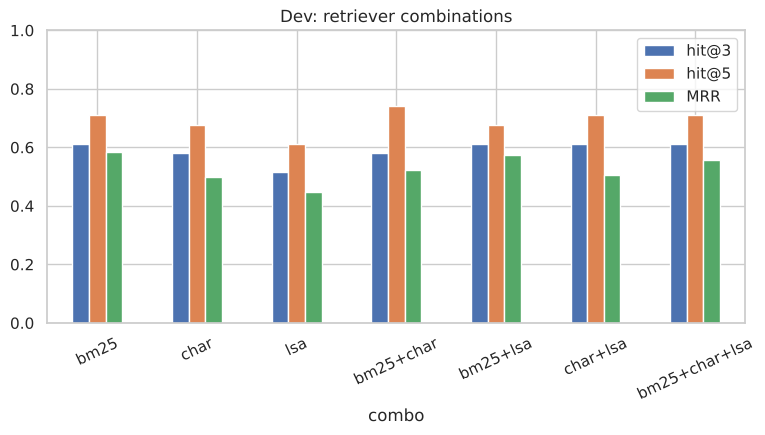

In [18]:
fus[['hit@3','hit@5','MRR']].plot(kind='bar',figsize=(9,3.8)); plt.xticks(rotation=25); plt.ylim(0,1); plt.title('Dev: retriever combinations'); plt.show()

Most differences are **within one or two questions** — i.e. noise with 31 dev questions. Choosing a setting that wins by one question would be overfitting to the dev set, so we choose by *reasoning*, not by the last decimal:

| Setting | Choice | Reason |
|---|---|---|
| Drop navigation chunks | yes | removes chunks that match everything |
| Exercise weight | 0.6 | mild; clearly helped the fused retriever on dev (hit@3 0.52 → 0.61) |
| Heading boost | 2 | headings name the concept |
| BM25 b | 0.75 (default) | no clear winner (smaller b looked slightly better on dev, within noise) |
| Chunk size | 1200 / 200 | no clear winner; keeps code blocks intact |
| Fusion | BM25 + char n-grams | a-priori argument: exact keywords **plus** robustness to glued API names |

**Honest caveat:** the table above does *not* show that fusion helps — on dev, BM25 alone has the highest MRR (0.585 vs 0.521) and ties on hit@5. We keep the fused retriever as the frozen default because the decision was made before looking at the test set, but you should read it as *“no evidence it is better than plain BM25”*. Switching is a one-word change (`method='bm25'`).

## 4. Freeze the configuration and evaluate on the TEST questions (once)

In [19]:
final = Index.build('data/notes')   # the defaults ARE the frozen configuration
print('config → drop_nav=True, kind_weights=', final.kind_weights, ', heading_boost=2, bm25_b=0.75, 1200/200 chars, hybrid = BM25 + char n-grams')
test_report = report(final, test); test_report

config → drop_nav=True, kind_weights= {'exercises': 0.6} , heading_boost=2, bm25_b=0.75, 1200/200 chars, hybrid = BM25 + char n-grams


,hit@1,hit@3,hit@5,hit@10,MRR
bm25,0.613,0.742,0.774,0.903,0.690
char,0.548,0.677,0.710,0.774,0.625
lsa,0.645,0.710,0.839,0.903,0.715
hybrid,0.613,0.710,0.742,0.871,0.680


In [20]:
report(final, dev).rename_axis('DEV (for reference)')

,hit@1,hit@3,hit@5,hit@10,MRR
DEV (for reference),,,,,
bm25,0.548,0.645,0.710,0.742,0.609
char,0.387,0.581,0.677,0.774,0.511
lsa,0.355,0.548,0.645,0.710,0.473
hybrid,0.419,0.581,0.742,0.742,0.521


Scores on the test questions are **higher than on dev** for every method, and the ranking of methods changes (LSA has the best hit@5 here but the worst on dev). That is what noise looks like with 31 questions per split, so do not read a winner into either table.

### 4.1 How sure are we? Bootstrap confidence intervals

In [21]:
def boot(ranks, k, B=2000, seed=0):
    rng=np.random.default_rng(seed); hit=np.array([r is not None and r<=k for r in ranks],float)
    m=[rng.choice(hit,len(hit)).mean() for _ in range(B)]; return hit.mean(), np.percentile(m,2.5), np.percentile(m,97.5)
rows=[]
for m in ['bm25','char','lsa','hybrid']:
    _,rk=retrieval_metrics(final,test,m)
    for k in (3,5):
        mean,lo,hi=boot(rk,k); rows.append(dict(method=m,k=k,hit=round(mean,3),ci95=f'[{lo:.2f}, {hi:.2f}]'))
pd.DataFrame(rows).pivot(index='method',columns='k',values=['hit','ci95'])

hit                 ci95              
k           3      5             3             5
method                                          
bm25    0.742  0.774  [0.58, 0.87]  [0.61, 0.90]
char    0.677   0.71  [0.52, 0.84]  [0.55, 0.87]
hybrid   0.71  0.742  [0.55, 0.87]  [0.58, 0.87]
lsa      0.71  0.839  [0.55, 0.87]  [0.71, 0.97]

The intervals are **wide** (roughly ±15 points) and overlap completely. The honest conclusion: all four methods find the right passage in the top 5 for roughly 60–85% of questions, and this evaluation is too small to rank them.

## 5. Where does retrieval work and where does it fail? (all 62 questions, descriptive)

In [22]:
allq=golden['in_scope']; _,rk=retrieval_metrics(final,allq,'hybrid')
byq=pd.DataFrame(dict(question=[i['question'] for i in allq], series=[i['targets'][0][0].split('/')[0] for i in allq], rank=rk))
byq['hit5']=byq['rank'].apply(lambda r: r is not None and r<=5)
byq.groupby('series').agg(questions=('hit5','size'), hit5=('hit5','mean')).round(2)

,questions,hit5
series,,
exercises,3,0.67
interview-qa,2,1.00
matplotlib,8,0.62
numpy,20,0.65
pandas,14,0.71
scikit-learn,10,0.90
seaborn,5,1.00


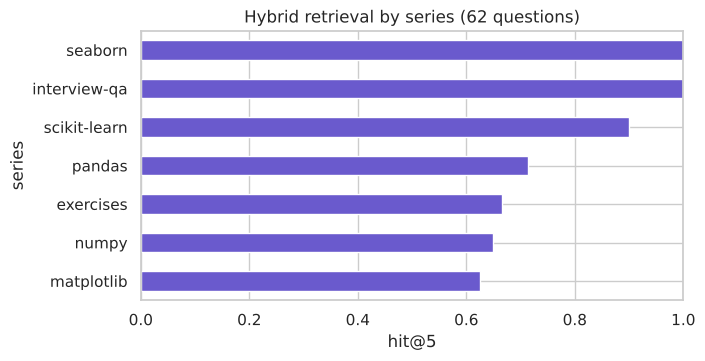

In [23]:
byq.groupby('series').hit5.mean().sort_values().plot(kind='barh',color='slateblue',figsize=(7,3.5)); plt.xlim(0,1); plt.xlabel('hit@5'); plt.title('Hybrid retrieval by series (62 questions)'); plt.show()

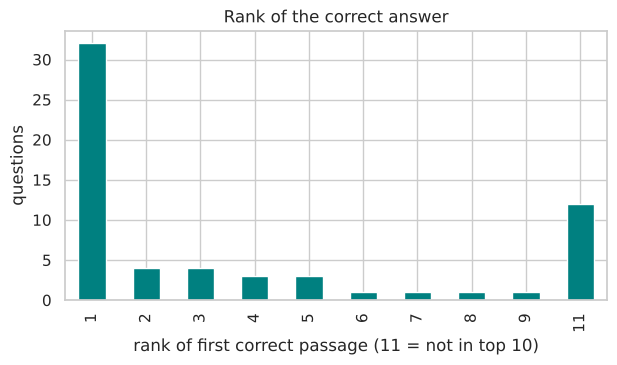

In [24]:
pd.Series([r if r is not None else 11 for r in rk]).value_counts().sort_index().plot(kind='bar',color='teal',figsize=(7,3.5)); plt.xlabel('rank of first correct passage (11 = not in top 10)'); plt.ylabel('questions'); plt.title('Rank of the correct answer'); plt.show()

In [25]:
miss=byq[byq['rank'].isna() | (byq['rank']>5)]; print(len(miss),'questions where the right passage is not in the top 5'); miss[['question','rank']]

16 questions where the right passage is not in the top 5


,question,rank
2,How can I turn a 1-D array of 12 numbers into ...,NaN
4,How do I find the position of the largest elem...,NaN
6,How can I remove duplicate values from an array?,NaN
7,How do I test whether each element belongs to ...,NaN
10,What does -1 mean when reshaping an array?,NaN
13,How do I select all elements greater than 10 u...,NaN
16,Why does adding large numbers to an int8 array...,NaN
21,How do I fill missing values with the column a...,8.0
31,How do I get rid of repeated rows?,6.0
32,How do I get the n rows with the highest value...,NaN


### 5.1 Why do these still fail?

In [26]:
rows=[]
for it in allq:
    rk_=rank_of_first_hit(final,it,'hybrid',10); top=final.search(it['question'],3); want=it['targets'][0][0].split('/')[0]
    rows.append(dict(missed=(rk_ is None or rk_>5), exercise_share=np.mean([c.kind=='exercises' for c,_ in top]), right_series_in_top3=any(c.series==want or (want=='exercises' and c.kind=='exercises') for c,_ in top)))
d=pd.DataFrame(rows); print('exercise share of top-3 results, all questions: %.0f%%  |  missed questions: %.0f%%' % (d.exercise_share.mean()*100, d[d.missed].exercise_share.mean()*100)); print('missed questions where the top-3 still contains a passage from the RIGHT series: %.0f%%' % (d[d.missed].right_series_in_top3.mean()*100))

exercise share of top-3 results, all questions: 1%  |  missed questions: 0%
missed questions where the top-3 still contains a passage from the RIGHT series: 69%


In [27]:
for q in list(miss.question)[:6]:
    it=next(i for i in allq if i['question']==q); top=final.search(q,3)
    print('Q:',q); print('   wanted :', it['targets'][0][1]); print('   top-3  :', ' || '.join(c.section.split(' > ')[-1][:38] for c,_ in top)); print()

Q: How can I turn a 1-D array of 12 numbers into a 3x4 table?
   wanted : reshape()
   top-3  : 15. `np.vectorize()` — Turning a Pytho || Table Embedded in a Plot || 19g. Complex Numbers in NumPy

Q: How do I find the position of the largest element in an array?
   wanted : argmax()
   top-3  : 4. Accessing Series Elements || 7. `np.nonzero()` — Locating Non-Zero  || 2. `np.searchsorted()` — Binary Search

Q: How can I remove duplicate values from an array?
   wanted : np.unique()
   top-3  : Q24. (Bonus) Find and remove duplicate || 18. Checking for Duplicate Rows || 4. Removing Duplicate Rows

Q: How do I test whether each element belongs to a given list of values?
   wanted : isin()
   top-3  : 3. Why NumPy instead of Python Lists? || Q22. Given a DataFrame of 10 real-numb || Q21. How do you subtract the row mean 

Q: What does -1 mean when reshaping an array?
   wanted : Using `-1`
   top-3  : 22. `np.repeat()` vs `np.tile()` in Re || 13. `resize()` — Reshape That Can Chan || 04 — 

Two things are visible:

1. **The exercise crowding is fixed** — exercises are now a tiny share of top-3 results (see the cell above), so that was a real, solved problem.
2. **The remaining misses are mostly vocabulary mismatch.** In about 7 of 10 misses the top 3 *does* contain a passage from the right library, so the retriever found the right *area* but not the right *section*: the question says *“rescale features to lie between 0 and 1”* while the note says *MinMaxScaler*; *“whiskers”* vs *Error Bars*; *“colour map”* returns an Array-Creation chunk. A few are word-form accidents (*“get rid of repeated rows”* returns `np.repeat` / `np.tile` because our light stemmer maps *repeated* → *repeat*) and a few are NumPy/Pandas mix-ups (*“remove duplicate values from an array”* lands on the pandas duplicate-row notes). Keyword methods cannot bridge a vocabulary gap; **neural sentence embeddings** (e.g. MiniLM) are the usual fix, which is why the project has an optional embedding backend — see §7. Restricting the search to one series (an option in the app) only helps the minority of cross-library mix-ups.

## 6. Speed

In [28]:
qs=[i['question'] for i in allq]
for m in ['bm25','char','lsa','hybrid']:
    t=time.time(); [final.search(q,5,m) for q in qs]; print(f'{m:7s} {(time.time()-t)/len(qs)*1000:6.1f} ms per query')

bm25       0.5 ms per query
char       1.5 ms per query


lsa        2.8 ms per query
hybrid     2.3 ms per query


In [29]:
t=time.time(); Index.build('data/notes'); print(f'full index build: {time.time()-t:.1f}s for {len(final.chunks)} chunks')

full index build: 1.2s for 582 chunks


## 7. Optional: neural embeddings (not run here)

`python scripts/eval_minilm.py` builds the same index **plus** `sentence-transformers/all-MiniLM-L6-v2` embeddings and prints the same table on the same dev/test split. It needs `pip install sentence-transformers` and internet access for the first download — neither was available in the environment where I built this project, so **I have not measured it, and I do not claim it is better.** The expectation, from the failure analysis above, is that it helps the vocabulary-mismatch questions.

In [30]:
import importlib.util; print('sentence-transformers installed here:', importlib.util.find_spec('sentence_transformers') is not None)

sentence-transformers installed here: False


## 8. Save the results

In [31]:
res=pd.concat({'dev':report(final,dev),'test':report(final,test)}); res.to_csv('eval/results_retrieval.csv'); res

hit@1  hit@3  hit@5  hit@10    MRR
dev  bm25    0.548  0.645  0.710   0.742  0.609
     char    0.387  0.581  0.677   0.774  0.511
     lsa     0.355  0.548  0.645   0.710  0.473
     hybrid  0.419  0.581  0.742   0.742  0.521
test bm25    0.613  0.742  0.774   0.903  0.690
     char    0.548  0.677  0.710   0.774  0.625
     lsa     0.645  0.710  0.839   0.903  0.715
     hybrid  0.613  0.710  0.742   0.871  0.680

## 9. Summary
| Question | Answer |
|---|---|
| Which retriever? | BM25 + character n-grams (RRF) was frozen by reasoning; **plain BM25 did at least as well** — no method is clearly best at this sample size |
| Biggest practical problem found and fixed | tiny exercise chunks crowding out real answers (now ≈1% of top-3) |
| Final scores | see the TEST table in §4 (with wide confidence intervals) |
| Remaining failure types | vocabulary mismatch (right library, wrong section) and some NumPy/Pandas mix-ups → neural embeddings (not measured here) |
| What was *not* done | tuning on test; claiming differences smaller than the noise |

**Next:** [03 – Answers, citations & refusing out-of-scope questions](03_answers_and_refusal.ipynb)